# CEC

> Transfer of a CNN for cation exchange capacity (CEC) from OSSL to Fukushima: zero-shot, head-only, fine-tuned, fully fine-tuned and Fukushima-only models

In [ ]:
import numpy as np, pandas as pd
from fastcore.test import *
from soilspecdata.all import load_ossl
from ossl_fuku_transfer.data import *
from ossl_fuku_transfer.transfer import *

/Users/franckalbinet/pro/dev/soilspec/ossl-fuku-transfer/.venv/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Every code cell reads OSSL or the Fukushima data, and is marked `#| fukudata`. The outputs come from a local run on an Apple silicon GPU (MPS). `02_transfer` defines the functions used here.

## Data

OSSL MIR spectra on the shared grid, with CEC in cmolc/kg. The models predict `log1p(CEC)`:

In [ ]:
#| fukudata
om = load_ossl().mir(wmin=shared_wns[0], wmax=shared_wns[-1])
Xo, yo, _ = om.xy('cec_usda.a723_cmolc.kg')
yo = np.log1p(yo.ravel())
Xo.shape

(57062, 1675)

The Fukushima spectra, with CEC in meq/100 g, which equals cmolc/kg. The test set is the Cs137 study's test set:

In [ ]:
#| fukudata
fuku = load_fuku()
fuku.source = fuku.source.assign(target=fuku.source['soil_CEC'])
Xf, yf, idf = fuku.xy('target')
yf = np.log1p(yf.ravel())
_, test_ids = cs137_split()
is_test = np.isin(idf, test_ids)
yt = yf[is_test]
Xf.shape, int(is_test.sum())

((1386, 1675), 340)

## Pretraining

Each preprocessing is fitted on OSSL and applied to Fukushima. `pretrain` trains on OSSL, or loads the weights of an earlier run. The table shows the last epoch of each pretraining, with the R² of the OSSL validation set:

In [ ]:
#| fukudata
X = {k: (p.fit_transform(Xo), p.transform(Xf)) for k, p in preprocessings().items()}
pretrained = {k: pretrain(Xo_k, yo, f'ossl_cec_{k}') for k, (Xo_k, _) in X.items()}
pd.DataFrame({k: pretrain_history(f'ossl_cec_{k}').iloc[-1] for k in X}).T.round(3)

,train_loss,valid_loss,r2_score
snv,0.042,0.031,0.962
snv_d1,0.037,0.028,0.966


## Comparison

Each Fukushima model trains with five seeds. The table gives the mean and standard deviation over the seeds of R² and correlation `r` of `log1p(CEC)`, and of the RMSE and bias of CEC in cmolc/kg, on the test samples:

In [ ]:
#| fukudata
res, preds = compare(pretrained, {k: Xf_k for k, (_, Xf_k) in X.items()}, yf, is_test)
summarise(res).round(3)

R²             r  ...          bias       
                                 mean    std   mean  ...    std   mean    std
preprocessing model                                  ...                     
snv           zero-shot        -3.831  0.000  0.477  ...  0.000 -7.670  0.000
              head only         0.294  0.006  0.592  ...  0.021 -0.872  0.061
              fine-tuned        0.336  0.005  0.613  ...  0.018 -0.388  0.083
              fully fine-tuned  0.689  0.004  0.831  ...  0.018 -0.324  0.044
              Fukushima only    0.482  0.009  0.708  ...  0.061 -0.760  0.255
snv_d1        zero-shot        -0.695  0.000  0.572  ...  0.000 -2.994  0.000
              head only         0.314  0.003  0.610  ...  0.015 -0.293  0.077
              fine-tuned        0.388  0.002  0.647  ...  0.007 -0.260  0.060
              fully fine-tuned  0.718  0.005  0.848  ...  0.020 -0.301  0.042
              Fukushima only    0.593  0.006  0.781  ...  0.034 -0.906  0.246

[10 rows x 8 columns]

For scale, the standard deviation of the test CEC values, in cmolc/kg:

In [ ]:
#| fukudata
round(float(np.expm1(yt).std()), 3)

5.612

Predictions of the first seed against the observed values:

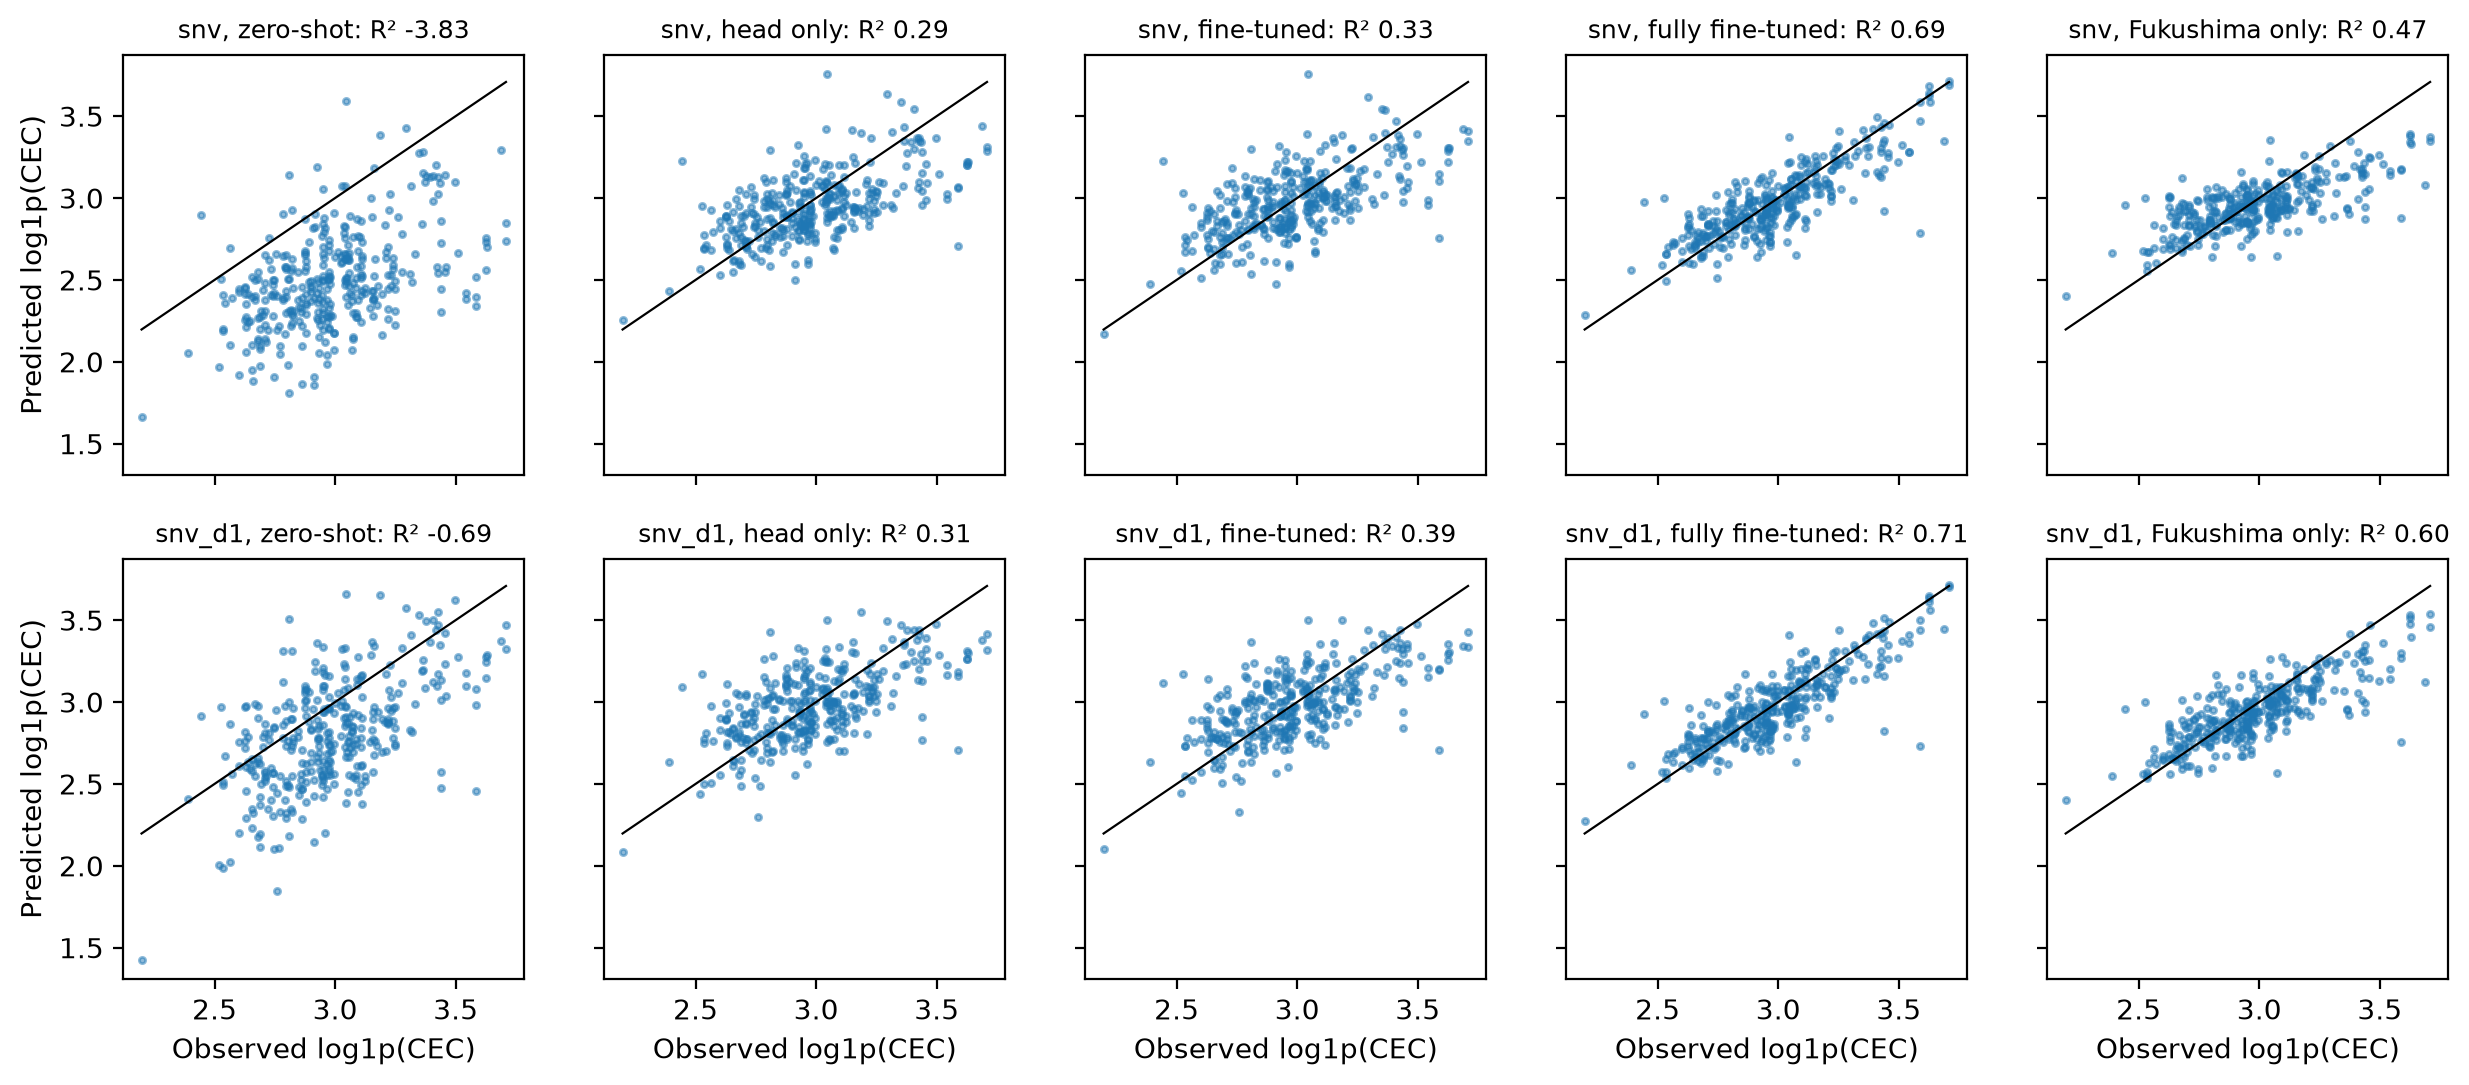

In [ ]:
#| fukudata
plot_preds(preds, yt, label='log1p(CEC)');

## Checks

The OSSL validation R² covers OSSL's whole CEC range. The pretrained models are scored again on their OSSL validation samples, first all of them, then those within the 5th to 95th percentile of Fukushima CEC:

In [ ]:
#| fukudata
lo, hi = np.quantile(yf, [0.05, 0.95])
np.expm1([lo, hi]).round(2), pd.DataFrame({k: range_check(Xo_k, yo, pretrained[k], lo, hi) for k, (Xo_k, _) in X.items()}).T.round(3)

(array([11.2 , 30.77]),
          n all  R² all  r all  n in range  R² in range  r in range
 snv     5706.0   0.962  0.981      2677.0        0.621       0.841
 snv_d1  5706.0   0.966  0.983      2677.0        0.660       0.857)

## Error analysis

Mean absolute error of `log1p(CEC)` with the derivative preprocessing, by soil type, year and measurement batch. Each model's predictions are averaged over the seeds first:

In [ ]:
#| fukudata
props = fuku.source.loc[idf[is_test]]
error_table(preds, yt, props['Soil_type_describe'], 'snv_d1').round(3)

,head only,fine-tuned,fully fine-tuned,Fukushima only,n
Andosols,0.161,0.153,0.117,0.163,44
Forest soil,0.204,0.194,0.087,0.097,27
Glay soil,0.171,0.160,0.084,0.074,6
Lowland soil,0.169,0.158,0.099,0.116,243
Peat soil,0.150,0.133,0.079,0.132,14
Red yellow soil,0.129,0.118,0.081,0.080,6


In [ ]:
#| fukudata
error_table(preds, yt, props['year'].astype(int), 'snv_d1').round(3)

,head only,fine-tuned,fully fine-tuned,Fukushima only,n
2013,0.205,0.195,0.144,0.142,34
2014,0.162,0.138,0.081,0.107,53
2015,0.143,0.137,0.095,0.112,48
2016,0.154,0.147,0.079,0.098,58
2017,0.181,0.167,0.095,0.130,37
2018,0.217,0.204,0.122,0.138,46
2019,0.136,0.132,0.096,0.118,48
2020,0.184,0.174,0.107,0.146,16


In [ ]:
#| fukudata
error_table(preds, yt, sample_batches(idf[is_test]), 'snv_d1').round(3)

,head only,fine-tuned,fully fine-tuned,Fukushima only,n
batch 1,0.193,0.176,0.108,0.124,110
batch 2,0.158,0.150,0.095,0.118,230


## Findings

The pretrained models come from one pretraining run each. The Fukushima-side training was repeated with five seeds, and the standard deviations over the seeds are at most about 0.01 in R² for the models compared below. Training on MPS is not fully deterministic, and the variation between pretraining runs is not measured. Neither the fully fine-tuned nor the Fukushima-only schedule was tuned: both train for 21 one-cycle epochs at a maximum learning rate of 1e-3.

Pretraining on OSSL helps, once the whole network trains on Fukushima. The fully fine-tuned model reaches an R² of `log1p(CEC)` of 0.72, a correlation of 0.85 and an RMSE of 2.9 cmolc/kg with the derivative. The same CNN trained on Fukushima only reaches 0.59, 0.78 and 3.7 cmolc/kg. With SNV the gap is larger: 0.69 against 0.48. The standard deviation of the test CEC values is 5.6 cmolc/kg.

The OSSL backbone does not work unchanged. Without training, it partly ranks the Fukushima samples (correlation 0.48 with SNV and 0.57 with the derivative), but predicts much too low: the bias is -7.7 cmolc/kg with SNV and -3.0 with the derivative, against a median Fukushima CEC of 18 cmolc/kg. A linear head on the frozen backbone gives an R² of 0.31. fastai's `fine_tune`, whose backbone trains at a maximum learning rate of 5e-6, gives 0.39. The OSSL weights are a useful starting point, but the backbone has to adapt to the Fukushima spectra.

Pretraining reaches an OSSL validation R² of 0.96 with SNV and 0.97 with the derivative. On OSSL validation samples within Fukushima's CEC range (11.2 to 30.8 cmolc/kg), the R² is 0.62 and 0.66 and the correlation 0.84 and 0.86. The fully fine-tuned model does about as well on Fukushima as the OSSL model does on OSSL samples in the same range.

The fully fine-tuned model has the lowest error in almost every year and batch, and in most soil types. Its largest gain over the Fukushima-only model is for Andosols and peat soils, but those groups have 44 and 14 test samples.